# 🛡️ Early Warning Risk Predictor
### Predicting tomorrow's air-threat risk for each Saudi region from Civil Defense alerts

Group members:

# 1. Problem Definition

### The problem
Since September 2026, Saudi Arabia has faced repeated missile and drone threats. The **Civil Defense (@SaudiDCD)** posts an **early warning alert** on X when a threat is detected over a region, and a **"danger cleared"** post a few minutes later.

These alerts tell people what is happening **now**, but nobody can tell them **what to expect tomorrow**. Families, schools and workplaces have to plan their day without knowing whether their region is likely to be targeted.

### Our solution
Using the history of official alerts, we build a tool that gives, **for each region**:

| Output | Question it answers | How |
|---|---|---|
| **Tomorrow's risk** | *"How likely is an alert in my region tomorrow?"* | **Model 1**: binary classification |
| **Time of risk** | *"If there is an alert, at what time of day is it most likely?"* | **Model 2**: multi-class classification (Night / Morning / Afternoon / Evening) |
| **Time to clear** | *"How long does the danger usually last?"* | **Statistics** (median alert duration per region), no model needed |

### Who is it for?
Residents, schools and workplaces in the affected regions, to plan the next day with better awareness.

### How we will judge success
- Each model must **beat a simple baseline** (always predicting the most common answer). If a model can't, it isn't useful.
- For Model 1, **missing a real attack is worse than a false alarm**, so we focus on **Recall** and **ROC-AUC**, not only accuracy.

### Limitations (stated upfront)
- Attacks depend on political and military decisions that are **not in the data**, so the model estimates **risk from past patterns**, not certainty.
- The dataset covers about **10 weeks**, so results should be treated as a proof of concept.
- `school_in_person` is a **synthetic feature** (explained in section 4), approved by our instructor.
- This tool **does not replace official warnings**. Always follow @SaudiDCD instructions.

# 2. Data Collection & Understanding

### Source
We **collected the data ourselves** from the official Civil Defense account **[@SaudiDCD](https://x.com/SaudiDCD)**, from **1 September to 10 November 2026**. Every alert tweet and every "danger cleared" tweet was recorded, and each pair is linked by an `Alert_ID`.

| Column | Meaning |
|---|---|
| `Tweet_ID`, `Tweet_URL` | Link to the original tweet (for verification) |
| `Tweet_Type` | **Alert** (early warning) or **Clear** (danger is over) |
| `Alert_ID` | Links each Clear tweet to its Alert |
| `Day`, `Date`, `Time` | When the tweet was posted |
| `Region`, `City` | Where the alert applies (City is sometimes not specified) |
| `Source_Account` | Always @SaudiDCD |

### 2.1 Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
START_DATE = "2026-09-01"            # first day of data collection
WEEKEND = ["Friday", "Saturday"]     # Saudi weekend
PERIODS = ["Night", "Morning", "Afternoon", "Evening"]

### 2.2 Loading the data

In [2]:
raw = pd.read_csv("SaudiDCD_alerts.csv")
raw.head()

,Tweet_ID,Tweet_URL,Tweet_Type,Alert_ID,Day,Date,Time,Region,City,Source_Account
0,2097368405519094132,https://x.com/SaudiDCD/status/2097368405519094132,Alert,AL-001,Tuesday,2026-09-08,19:56,Jazan,NaN,@SaudiDCD
1,2097369128520585503,https://x.com/SaudiDCD/status/2097369128520585503,Alert,AL-002,Tuesday,2026-09-08,19:59,Asir,Abha,@SaudiDCD
2,2097369789278658934,https://x.com/SaudiDCD/status/2097369789278658934,Alert,AL-003,Tuesday,2026-09-08,20:01,Najran,NaN,@SaudiDCD
3,2097370230137729514,https://x.com/SaudiDCD/status/2097370230137729514,Clear,AL-001,Tuesday,2026-09-08,20:03,Jazan,NaN,@SaudiDCD
4,2097370721210999166,https://x.com/SaudiDCD/status/2097370721210999166,Clear,AL-002,Tuesday,2026-09-08,20:05,Asir,Abha,@SaudiDCD


In [3]:
print("Shape:", raw.shape)
print()
raw.info()

Shape: (382, 10)

<class 'pandas.DataFrame'>
RangeIndex: 382 entries, 0 to 381
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Tweet_ID        382 non-null    int64
 1   Tweet_URL       382 non-null    str  
 2   Tweet_Type      382 non-null    str  
 3   Alert_ID        380 non-null    str  
 4   Day             382 non-null    str  
 5   Date            382 non-null    str  
 6   Time            382 non-null    str  
 7   Region          382 non-null    str  
 8   City            286 non-null    str  
 9   Source_Account  382 non-null    str  
dtypes: int64(1), str(9)
memory usage: 30.0 KB


In [4]:
print("Tweet types:", raw["Tweet_Type"].value_counts().to_dict())
print("Duplicate rows:", raw.duplicated().sum())
print("\nMissing values:")
print(raw.isnull().sum()[raw.isnull().sum() > 0])

Tweet types: {'Clear': 192, 'Alert': 190}
Duplicate rows: 0

Missing values:
Alert_ID     2
City        96
dtype: int64


**Interpretation:**
- **382 tweets**: 190 alerts and 192 "clear" tweets, with **no duplicates**.
- `City` is missing in 96 tweets. This is normal, because some alerts cover a whole region without naming a city. We use `Region` for modelling, so this doesn't affect us.
- `Alert_ID` is missing in **2 tweets**. We check them next.

### 2.3 Data cleaning: pairing each alert with its "clear" tweet

In [5]:
raw[raw["Alert_ID"].isna()]

,Tweet_ID,Tweet_URL,Tweet_Type,Alert_ID,Day,Date,Time,Region,City,Source_Account
264,2114257150889300324,https://x.com/SaudiDCD/status/2114257150889300324,Clear,NaN,Sunday,2026-10-25,10:26,Asir,Al Namas,@SaudiDCD
266,2114257613508534448,https://x.com/SaudiDCD/status/2114257613508534448,Clear,NaN,Sunday,2026-10-25,10:27,Asir,Al Namas,@SaudiDCD


These are two **"clear" tweets for Al Namas** with **no matching alert** in the data. Without an alert, we can't know when the danger started, so we **drop them**.

In [6]:
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"])
raw = raw.dropna(subset=["Alert_ID"])

alerts = raw[raw["Tweet_Type"] == "Alert"].copy()
clears = raw[raw["Tweet_Type"] == "Clear"][["Alert_ID", "datetime"]].rename(columns={"datetime": "clear_datetime"})

alerts = alerts.merge(clears, on="Alert_ID", how="left")
print("Alerts:", len(alerts), "| Alerts without a clear tweet:", alerts["clear_datetime"].isna().sum())

Alerts: 190 | Alerts without a clear tweet: 0


Every alert has its matching "clear" tweet. Now we add the columns we need for the analysis:

In [7]:
def period_of(hour):
    if hour < 6:
        return "Night"        # 00:00-05:59
    elif hour < 12:
        return "Morning"      # 06:00-11:59
    elif hour < 18:
        return "Afternoon"    # 12:00-17:59
    else:
        return "Evening"      # 18:00-23:59

alerts["duration_min"] = (alerts["clear_datetime"] - alerts["datetime"]).dt.total_seconds() / 60
alerts["date"] = alerts["datetime"].dt.normalize()
alerts["hour"] = alerts["datetime"].dt.hour
alerts["period"] = alerts["hour"].apply(period_of)
alerts["weekday"] = alerts["datetime"].dt.day_name()
alerts["is_weekend"] = alerts["weekday"].isin(WEEKEND).astype(int)
alerts = alerts.sort_values("datetime").reset_index(drop=True)

alerts[["Alert_ID", "Region", "City", "datetime", "clear_datetime", "duration_min", "period"]].head()

,Alert_ID,Region,City,datetime,clear_datetime,duration_min,period
0,AL-001,Jazan,NaN,2026-09-08 19:56:00,2026-09-08 20:03:00,7.0,Evening
1,AL-002,Asir,Abha,2026-09-08 19:59:00,2026-09-08 20:05:00,6.0,Evening
2,AL-003,Najran,NaN,2026-09-08 20:01:00,2026-09-08 20:07:00,6.0,Evening
3,AL-004,Asir,Khamis Mushait,2026-09-09 09:24:00,2026-09-09 09:27:00,3.0,Morning
4,AL-005,Asir,Khamis Mushait,2026-09-09 17:24:00,2026-09-09 17:32:00,8.0,Afternoon


In [8]:
alerts["duration_min"].describe().round(1)

,duration_min
count,190.0
mean,8.7
std,7.2
min,0.0
25%,4.2
50%,7.0
75%,10.0
max,53.0


**Interpretation:** a typical alert lasts **7 minutes** (median), and 75% are cleared within **10 minutes**. The longest lasted **53 minutes**.

Two alerts have a duration of **0 minutes**: the alert and the clear were posted in the same minute. They are real tweets, so we keep them.

# 3. Exploratory Data Analysis (EDA)

### 3.1 Alerts over time

Days in the data: 71
Days with at least one alert: 45 (63%)
Busiest days: {Timestamp('2026-09-15 00:00:00'): 16, Timestamp('2026-09-14 00:00:00'): 14, Timestamp('2026-09-18 00:00:00'): 11}


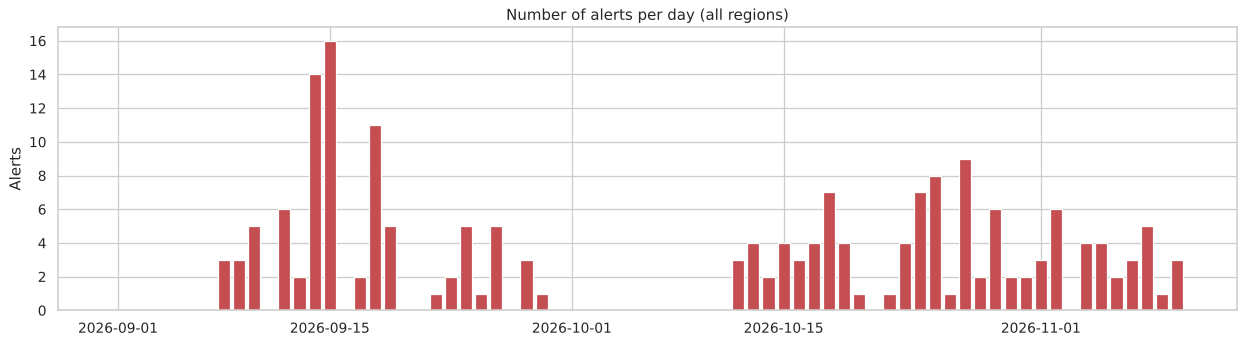

In [9]:
days = pd.date_range(START_DATE, alerts["date"].max(), freq="D")
daily_counts = alerts.groupby("date").size().reindex(days, fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(daily_counts.index, daily_counts.values, color="#C44E52")
ax.set_title("Number of alerts per day (all regions)")
ax.set_ylabel("Alerts")
plt.tight_layout()
plt.show()

print("Days in the data:", len(days))
print("Days with at least one alert:", (daily_counts > 0).sum(), f"({(daily_counts > 0).mean():.0%})")
print("Busiest days:", daily_counts.sort_values(ascending=False).head(3).to_dict())

**Interpretation:**
- The first alert was on **8 September**. After that, the alerts come in **waves**: a heavy period in mid-September (up to **16 alerts on 15 September**), then an almost completely **quiet period of about two weeks** (early October), then steady activity again from mid-October.
- This tells us that **recent activity matters**: an active week tends to be followed by more alerts, and a quiet week by quiet days. Features like *"alerts in the last 3 / 7 days"* and *"days since the last alert"* should capture this.

### 3.2 Which regions are targeted?

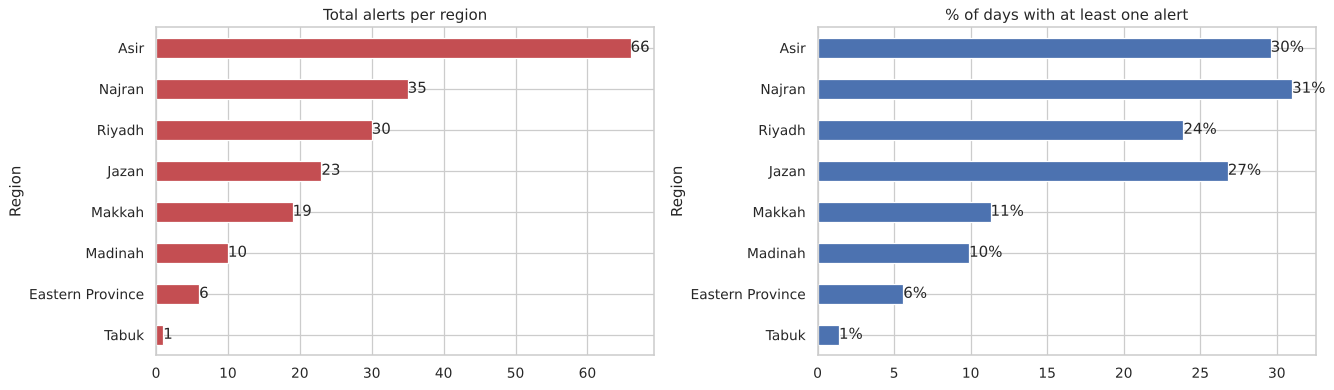

In [10]:
region_counts = alerts["Region"].value_counts()
regions = region_counts.index.tolist()

per_region_day = alerts.groupby(["date", "Region"]).size().unstack(fill_value=0).reindex(index=days, columns=regions, fill_value=0)
share_days = (per_region_day > 0).mean().round(3)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
region_counts.plot(kind="barh", ax=axes[0], color="#C44E52")
axes[0].invert_yaxis()
axes[0].set_title("Total alerts per region")
axes[0].bar_label(axes[0].containers[0])

(share_days * 100).plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].invert_yaxis()
axes[1].set_title("% of days with at least one alert")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f%%")
plt.tight_layout()
plt.show()

**Interpretation:**
- **Asir** is by far the most targeted region (**66 alerts**, mainly Khamis Mushait and Abha), followed by **Najran**, **Riyadh** and **Jazan**. The southern regions near the Yemeni border are hit most often.
- The right chart is the most important one for **Model 1**: it shows how often each region has an alert on a given day, so it's the **share of "1"s in our target**. Even the most active regions, **Najran (31%)** and **Asir (30%)**, have alerts on fewer than 1 in 3 days, so for every region, "no alert" is the more common answer, and **accuracy alone would be misleading**.
- **Tabuk** has only **1 alert** and the **Eastern Province** only 6. We keep every region separate so the tool serves all of them, but the model will have very little to learn from for these regions, and will give them low risk.

### 3.3 At what time do alerts happen?

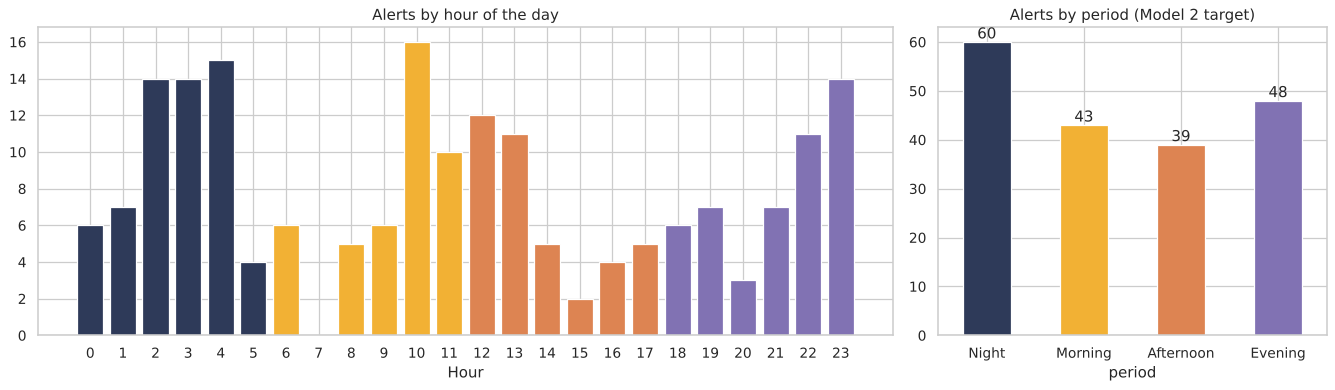

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

hour_counts = alerts["hour"].value_counts().reindex(range(24), fill_value=0)
colors = ["#2E3A59" if h < 6 else "#F2B134" if h < 12 else "#DD8452" if h < 18 else "#8172B3" for h in range(24)]
axes[0].bar(hour_counts.index, hour_counts.values, color=colors)
axes[0].set_xticks(range(24))
axes[0].set_title("Alerts by hour of the day")
axes[0].set_xlabel("Hour")

period_counts = alerts["period"].value_counts().reindex(PERIODS)
period_counts.plot(kind="bar", ax=axes[1], color=["#2E3A59", "#F2B134", "#DD8452", "#8172B3"], rot=0)
axes[1].set_title("Alerts by period (Model 2 target)")
axes[1].bar_label(axes[1].containers[0])
plt.tight_layout()
plt.show()

**Interpretation:**
- Alerts happen at **every time of day**, but there are two clear peaks: **late night to dawn (02:00–04:59)** and **late morning (10:00–12:59)**. The quietest hour is **07:00**, with no alerts at all.
- **Night** is the most common period (**60 alerts**). The four periods are reasonably **balanced** (37–60 alerts each), which is good for Model 2: no period dominates.
- A model that always predicts "Night" would be right only **32%** of the time. That's the **baseline** Model 2 must beat.

### 3.4 Does each region have its own time pattern?

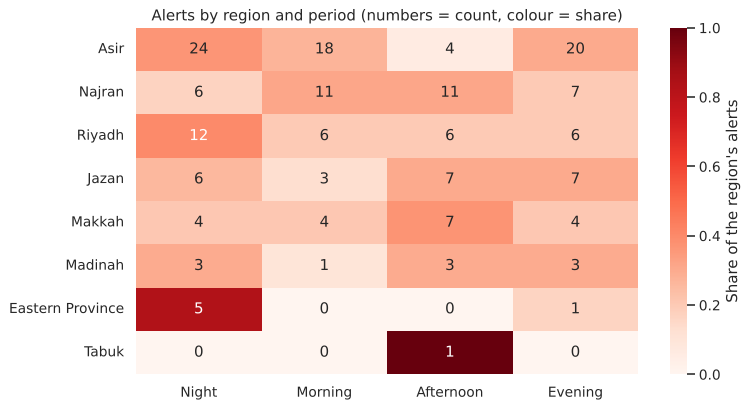

In [12]:
region_period = pd.crosstab(alerts["Region"], alerts["period"]).reindex(index=regions, columns=PERIODS)
region_period_pct = region_period.div(region_period.sum(axis=1), axis=0)

plt.figure(figsize=(9, 5))
sns.heatmap(region_period_pct, annot=region_period, fmt="d", cmap="Reds", cbar_kws={"label": "Share of the region's alerts"})
plt.title("Alerts by region and period (numbers = count, colour = share)")
plt.ylabel("")
plt.xlabel("")
plt.show()

**Interpretation:**
- **Asir** and **Riyadh** are hit mostly at **night** (36% and 40% of their alerts).
- **Najran** is different: most of its alerts are in the **morning and afternoon** (22 of 35).
- **Jazan** and **Makkah** are more spread out, with the afternoon slightly higher.

So the **region is a useful feature for Model 2**: knowing *where* helps predict *when*.

### 3.5 Day of the week

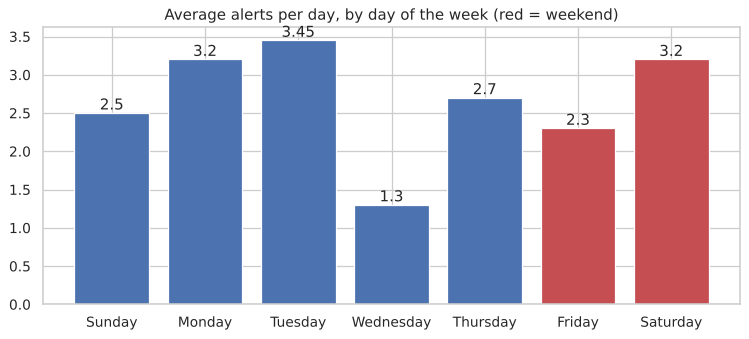

In [13]:
week_order = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
weekday_counts = alerts["weekday"].value_counts().reindex(week_order)
n_days = pd.Series(days.day_name()).value_counts().reindex(week_order)
per_day = (weekday_counts / n_days).round(2)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(week_order, per_day.values,
              color=["#C44E52" if d in WEEKEND else "#4C72B0" for d in week_order])
ax.bar_label(bars)
ax.set_title("Average alerts per day, by day of the week (red = weekend)")
plt.show()

**Interpretation:**
- **Tuesday** has the most alerts on average and **Wednesday** the fewest, but there's no clear difference between **weekdays and the weekend**.
- With only about 10 of each weekday in our data, these differences could be chance. So we use a **single `is_weekend` column** instead of seven weekday columns: it keeps the model simple, and we let the model decide whether it helps.

### 3.6 How long does the danger last?

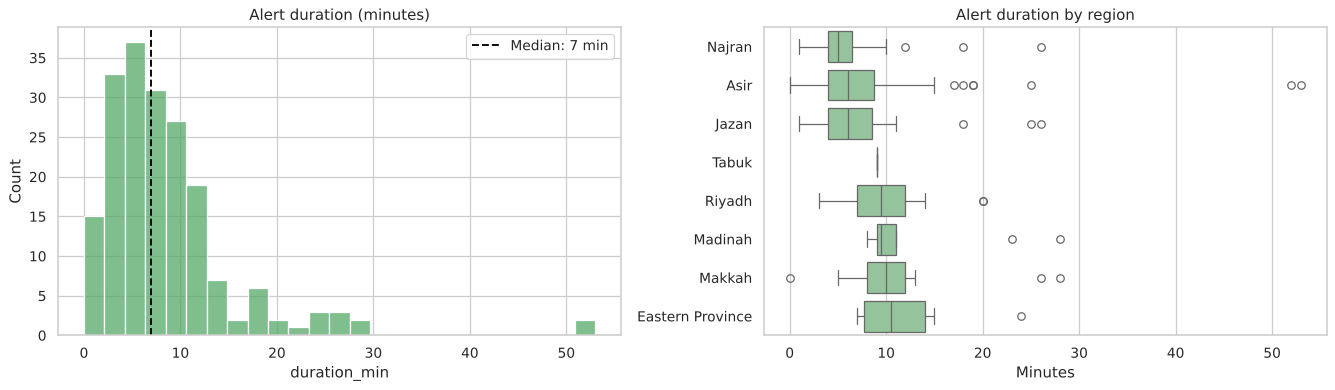

,median,mean,max,count
Region,,,,
Najran,5.0,6.0,26.0,35
Asir,6.0,8.5,53.0,66
Jazan,6.0,7.8,26.0,23
Tabuk,9.0,9.0,9.0,1
Riyadh,9.5,9.8,20.0,30
Madinah,9.5,12.7,28.0,10
Makkah,10.0,10.9,28.0,19
Eastern Province,10.5,12.3,24.0,6


In [14]:
order = alerts.groupby("Region")["duration_min"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(alerts["duration_min"], bins=25, ax=axes[0], color="#55A868")
axes[0].axvline(alerts["duration_min"].median(), color="black", linestyle="--", label="Median: 7 min")
axes[0].set_title("Alert duration (minutes)")
axes[0].legend()

sns.boxplot(data=alerts, y="Region", x="duration_min", order=order, ax=axes[1], color="#8DCB97")
axes[1].set_title("Alert duration by region")
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

alerts.groupby("Region")["duration_min"].agg(["median", "mean", "max", "count"]).round(1).sort_values("median")

**Interpretation:**
- Most alerts are cleared in **5 to 11 minutes**, with a few long ones (up to 53 minutes in Asir).
- **Najran (5 min)**, **Asir** and **Jazan (6 min)**, close to the border, clear **fastest**. **Riyadh, Makkah, Madinah and the Eastern Province (9.5–10.5 min)** take longer. A likely reason is that threats reaching deeper regions travel a longer distance.
- This variation is small and stable, so a **model isn't needed** for "time to clear". We show the **median duration of each region** in the app.

### 3.7 Are several regions hit at the same time?
We group alerts that happen within **60 minutes** of each other into one **attack wave**.

In [15]:
gap_min = alerts["datetime"].diff().dt.total_seconds() / 60
alerts["wave"] = (gap_min > 60).cumsum()
regions_per_wave = alerts.groupby("wave")["Region"].nunique()

print("Number of waves:", regions_per_wave.size)
print("Waves hitting more than one region:", (regions_per_wave > 1).sum())
regions_per_wave.value_counts().sort_index().rename("Waves").to_frame().rename_axis("Regions in the wave")

Number of waves: 98
Waves hitting more than one region: 25


,Waves
Regions in the wave,
1,73
2,19
3,4
4,2


**Interpretation:** the 190 alerts come from **98 waves**. Most waves hit a single region, but **25 waves (about 1 in 4)** hit **2 to 4 regions at once**. Regions are not completely independent, but each region still has its own rhythm, which supports building **features per region**, as we decided.

### 3.8 EDA summary: what we learned and how it shapes the next steps

| Finding | Decision for preprocessing and modelling |
|---|---|
| Alerts come in waves: busy weeks and quiet weeks | Use **recent activity** features: alerts today, last 3 days, last 7 days, days since the last alert, **per region** |
| Even the most-targeted region has alerts on fewer than 1 in 3 days | Model 1's target is **imbalanced**: use **Recall, F1 and ROC-AUC**, and compare with a baseline |
| Tabuk and the Eastern Province have very few alerts | Keep all 8 regions separate, but explain that their risk will stay low |
| Alerts happen at all hours, and the 4 periods are fairly balanced | Model 2 predicts the **period**, not the exact hour. Baseline = 32% |
| Each region has its own time pattern | Use **region** as a feature in Model 2 |
| No clear weekday vs weekend difference | One **`is_weekend`** column instead of 7 weekday columns |
| Duration is short and stable per region | No model needed: show the **median duration per region** |
| Time matters (waves, quiet periods) | Split train and test **by time**, never randomly |

# 4. Preprocessing

Our single dataset (one row per alert) is turned into **two tables**, one for each model:

| | Table 1: `daily` | Table 2: `timing` |
|---|---|---|
| Model | Model 1: tomorrow's risk | Model 2: time of risk |
| One row = | **one region on one day** | **one alert** |
| Rows | 71 days × 8 regions = 568 | 190 |
| Target | `attack_tomorrow` (0/1) | `period` (Night / Morning / Afternoon / Evening) |

**Golden rule for every feature:** it must be **known before the day we predict**. If a feature uses information from the future, the model "cheats" in training and fails in real use (this is called **data leakage**).

### 4.1 Table 1: daily risk per region (Model 1)
For each region and each day, we count what happened **up to and including that day**, and the target is whether the region has an alert **the next day**.

In [16]:
regions = sorted(alerts["Region"].unique())
days = pd.date_range(START_DATE, alerts["date"].max(), freq="D")

counts = (alerts.groupby(["date", "Region"]).size()
          .unstack(fill_value=0).reindex(index=days, columns=regions, fill_value=0))
dur_sum = (alerts.groupby(["date", "Region"])["duration_min"].sum()
           .unstack(fill_value=0).reindex(index=days, columns=regions, fill_value=0))

frames = []
for region in regions:
    c = counts[region]
    f = pd.DataFrame({"date": days, "Region": region})
    f["region_alerts_today"] = c.values
    f["region_alerts_last_3d"] = c.rolling(3, min_periods=1).sum().values
    f["region_alerts_last_7d"] = c.rolling(7, min_periods=1).sum().values

    # days since the last alert in this region (0 = alert today; before the first alert: days since START_DATE)
    last_seen, since = None, []
    for i, n in enumerate(c.values):
        if n > 0:
            last_seen = i
        since.append(i - last_seen if last_seen is not None else i + 1)
    f["region_days_since_last"] = since

    d7 = dur_sum[region].rolling(7, min_periods=1).sum()
    f["region_avg_duration_7d"] = (d7 / c.rolling(7, min_periods=1).sum().replace(0, np.nan)).fillna(0).round(1).values

    f["tomorrow_is_weekend"] = (days + pd.Timedelta(days=1)).day_name().isin(WEEKEND).astype(int)

    # TARGET: at least one alert in this region tomorrow (unknown for the last day)
    f["attack_tomorrow"] = (c.shift(-1) > 0).astype(float).values
    f.loc[f.index[-1], "attack_tomorrow"] = np.nan
    frames.append(f)

daily = pd.concat(frames).sort_values(["date", "Region"]).reset_index(drop=True)

# Saudi-wide activity: used ONLY in the comparison experiment in section 5
all_today = counts.sum(axis=1)
daily["all_alerts_last_7d"] = daily["date"].map(all_today.rolling(7, min_periods=1).sum())
daily["regions_hit_today"] = daily["date"].map((counts > 0).sum(axis=1))

print("Table 1 shape:", daily.shape)
daily[daily["Region"] == "Asir"].iloc[6:13]

Table 1 shape: (568, 11)


,date,Region,region_alerts_today,region_alerts_last_3d,region_alerts_last_7d,region_days_since_last,region_avg_duration_7d,tomorrow_is_weekend,attack_tomorrow,all_alerts_last_7d,regions_hit_today
48,2026-09-07,Asir,0,0.0,0.0,7,0.0,0,1.0,0.0,0
56,2026-09-08,Asir,1,1.0,1.0,0,6.0,0,1.0,3.0,3
64,2026-09-09,Asir,3,4.0,4.0,0,6.2,0,1.0,6.0,1
72,2026-09-10,Asir,5,9.0,9.0,0,6.3,1,0.0,11.0,1
80,2026-09-11,Asir,0,8.0,9.0,1,6.3,1,1.0,11.0,0
88,2026-09-12,Asir,4,9.0,13.0,0,7.2,0,1.0,17.0,3
96,2026-09-13,Asir,2,6.0,15.0,0,7.2,0,1.0,19.0,1


**How to read it (Asir, 7–13 September):**
- On **7 September** Asir had no alerts yet, so `region_days_since_last = 7` (days since we started collecting). The next day (8 Sep) had an alert, so `attack_tomorrow = 1`.
- On **10 September** Asir had **5 alerts**, so `region_alerts_last_3d = 9`, and `region_days_since_last = 0` (alert today). There was no alert on 11 September, so `attack_tomorrow = 0`.
- Every feature uses only the day itself and the days **before** it, while the target looks **one day ahead**. No information from the future leaks in.

| Feature | Meaning |
|---|---|
| `region_alerts_today` | Alerts in the region today |
| `region_alerts_last_3d`, `region_alerts_last_7d` | Alerts in the region over the last 3 / 7 days (today included) |
| `region_days_since_last` | Days since the region's last alert (0 = today) |
| `region_avg_duration_7d` | Average alert duration in the region over the last 7 days (0 if none) |
| `tomorrow_is_weekend` | Is tomorrow a Friday or Saturday? |
| `Region` | Which of the 8 regions (one-hot encoded later) |
| **`attack_tomorrow`** | **Target**: 1 if the region has at least one alert tomorrow |

In [17]:
balance = daily.dropna(subset=["attack_tomorrow"]).groupby("Region")["attack_tomorrow"].agg(["mean", "sum", "count"])
balance.columns = ["Share of 1s", "Days with attack tomorrow", "Rows"]
balance["Days with attack tomorrow"] = balance["Days with attack tomorrow"].astype(int)
balance["Share of 1s"] = (balance["Share of 1s"] * 100).round(1).astype(str) + "%"
balance.sort_values("Days with attack tomorrow", ascending=False)

,Share of 1s,Days with attack tomorrow,Rows
Region,,,
Najran,31.4%,22,70
Asir,30.0%,21,70
Jazan,27.1%,19,70
Riyadh,24.3%,17,70
Makkah,11.4%,8,70
Madinah,10.0%,7,70
Eastern Province,5.7%,4,70
Tabuk,1.4%,1,70


**Interpretation:** overall only about **18%** of the rows are "1". The model must learn the minority class, so we will use **`class_weight="balanced"`** and judge it with **Recall, F1 and ROC-AUC**, not accuracy.

### 4.2 The synthetic feature: `school_in_person`
Day-by-day data on in-person vs remote study per region isn't available to us, so, with our instructor's approval, we **simulate** it from two observations:
1. **Most high-risk regions studied remotely most of the time.** The high-risk regions are the four with an alert on about a quarter of all days or more (section 3.2): **Asir, Najran, Jazan and Riyadh**.
2. **Morning attacks often happened on days with in-person school.** For example, Riyadh returned to in-person study on Sunday 8 and Monday 9 November, and both days had morning alerts.

| Situation | `school_in_person` |
|---|---|
| Friday or Saturday | Always **0** (no school) |
| Days we know study was in-person / remote in the region | **1** / **0** |
| School day with a **morning alert** in the region | **1** with probability **90%** |
| Other school days in a **high-risk** region | **1** with probability **10%** (mostly remote) |
| Other school days in the other regions | **1** with probability **60%** |

The known days help make the simulation closer to reality:
- **Remote:** Asir on 15 September; Makkah from 27 September to 1 October; Riyadh from 27 September onward.
- **In-person:** Riyadh on 8 and 9 November.

Each region-day gets its own fixed random number, so the values are the same every time the notebook runs.

⚠️ This feature is built from the time of the attack, so we use it **only in Model 2 (time of risk)**. If we put it in Model 1, it would reveal the answer ("in-person tomorrow" → "morning attack tomorrow" → "attack tomorrow = 1"). In the app, the user tells us whether school is in-person tomorrow.

In [18]:
P_IN_PERSON_IF_MORNING = 0.90
P_IN_PERSON_HIGH_RISK = 0.10
P_IN_PERSON_OTHERWISE = 0.60
HIGH_RISK_REGIONS = ["Asir", "Najran", "Jazan", "Riyadh"]

def day_set(ranges):
    """(region, first day, last day) list -> set of (day, region)."""
    return {(day, region) for region, first, last in ranges
            for day in pd.date_range(first, last)}

# Days we know: (region, first day, last day)
known_in_person = day_set([
    ("Riyadh", "2026-11-08", "2026-11-09"),
])
known_remote = day_set([
    ("Asir",   "2026-09-15", "2026-09-15"),
    ("Makkah", "2026-09-27", "2026-10-01"),
    ("Riyadh", "2026-09-27", str(days.max().date())),
]) - known_in_person

# One fixed random number per (day, region)
rng = np.random.default_rng(RANDOM_STATE)
random_draw = pd.DataFrame(rng.random((len(days), len(regions))), index=days, columns=regions)

morning_days = set(zip(alerts.loc[alerts["period"] == "Morning", "date"],
                       alerts.loc[alerts["period"] == "Morning", "Region"]))
school_rows = []
for day in days:
    for region in regions:
        r = random_draw.loc[day, region]
        if day.day_name() in WEEKEND:
            value = 0
        elif (day, region) in known_in_person:
            value = 1
        elif (day, region) in known_remote:
            value = 0
        elif (day, region) in morning_days:
            value = int(r < P_IN_PERSON_IF_MORNING)
        elif region in HIGH_RISK_REGIONS:
            value = int(r < P_IN_PERSON_HIGH_RISK)
        else:
            value = int(r < P_IN_PERSON_OTHERWISE)
        school_rows.append((day, region, value))
school = pd.DataFrame(school_rows, columns=["date", "Region", "school_in_person"])

# Share of school days (Sun-Thu) with in-person study, per region
school_days = school[~school["date"].dt.day_name().isin(WEEKEND)]
(school_days.groupby("Region")["school_in_person"].mean() * 100).round(0).sort_values().rename("% in-person")

,% in-person
Region,
Riyadh,4.0
Jazan,20.0
Najran,20.0
Asir,22.0
Makkah,51.0
Eastern Province,57.0
Madinah,59.0
Tabuk,61.0


**Interpretation:** the high-risk regions are mostly remote (Riyadh 4%, Jazan and Najran 20%, Asir 22% of school days in-person), while the other regions are in-person on about half or more of school days.

### 4.3 Table 2: time of risk per alert (Model 2)
Each alert is one row. To predict the period of **tomorrow's** alerts, all features must be known **before that day starts**, so they only look at **earlier days**, never at other alerts on the same day.

In [19]:
timing = alerts.merge(school, on=["date", "Region"], how="left")
timing["prev_period_region"] = "First"
timing["region_days_since_prev"] = 0
timing["region_alerts_prev_7d"] = 0

for i, row in timing.iterrows():
    earlier = alerts[(alerts["Region"] == row["Region"]) & (alerts["date"] < row["date"])]
    if len(earlier) > 0:
        timing.at[i, "prev_period_region"] = earlier.iloc[-1]["period"]
        timing.at[i, "region_days_since_prev"] = (row["date"] - earlier.iloc[-1]["date"]).days
    else:
        timing.at[i, "region_days_since_prev"] = (row["date"] - pd.Timestamp(START_DATE)).days
    timing.at[i, "region_alerts_prev_7d"] = (earlier["date"] >= row["date"] - pd.Timedelta(days=7)).sum()

timing = timing[["Alert_ID", "date", "Region", "is_weekend", "school_in_person",
                 "prev_period_region", "region_days_since_prev", "region_alerts_prev_7d", "period"]]
print("Table 2 shape:", timing.shape)
timing.head(8)

Table 2 shape: (190, 9)


,Alert_ID,date,Region,is_weekend,school_in_person,prev_period_region,region_days_since_prev,region_alerts_prev_7d,period
0,AL-001,2026-09-08,Jazan,0,0,First,7,0,Evening
1,AL-002,2026-09-08,Asir,0,0,First,7,0,Evening
2,AL-003,2026-09-08,Najran,0,0,First,7,0,Evening
3,AL-004,2026-09-09,Asir,0,1,Evening,1,1,Morning
4,AL-005,2026-09-09,Asir,0,1,Evening,1,1,Afternoon
5,AL-006,2026-09-09,Asir,0,1,Evening,1,1,Afternoon
6,AL-007,2026-09-10,Asir,0,1,Afternoon,1,4,Night
7,AL-008,2026-09-10,Asir,0,1,Afternoon,1,4,Night


| Feature | Meaning |
|---|---|
| `Region` | Which region (one-hot encoded later) |
| `is_weekend` | Is the alert's day a Friday or Saturday? |
| `school_in_person` | Synthetic: in-person school in the region that day |
| `prev_period_region` | Period of the region's last alert on an **earlier day** (`First` = no earlier alert) |
| `region_days_since_prev` | Days since the region's last alert on an earlier day |
| `region_alerts_prev_7d` | Region's alerts in the 7 days **before** this day |
| **`period`** | **Target**: Night / Morning / Afternoon / Evening |

For example, the three Asir alerts on 9 September all share the same features (they're about the same day), but they have **different targets** (Morning, Afternoon, Afternoon). The model learns from all three.

In [20]:
pd.crosstab(timing["school_in_person"], timing["period"], margins=True)[PERIODS + ["All"]]

period,Night,Morning,Afternoon,Evening,All
school_in_person,,,,,
0,47,15,27,43,132
1,13,28,12,5,58
All,60,43,39,48,190


**Interpretation:** when school is in-person, **28 of 58 alerts (48%)** are in the morning. When it isn't, only **15 of 132 (11%)** are. The synthetic feature carries the pattern we observed, as intended, but it doesn't decide the answer alone, because in-person days still have many night and afternoon alerts.

### 4.4 Train / test split by time
Alerts come in waves, so a random split would put days from the **same wave** in both training and testing, and the model would look better than it really is. We split **by date**: train on the past, test on the most recent **3 weeks**, exactly like real use.

- **Train:** 1 September to 19 October 2026 (about 70% of the days)
- **Test:** 20 October to 9 November 2026 (10 November has no target yet: it's the day we predict from)

A 3-week test gives a **larger, more trustworthy test set** (74 alerts for Model 2, 46 attack days for Model 1), so one wrong prediction changes the result only a little.

In [21]:
SPLIT_DATE = pd.Timestamp("2026-10-20")

M1_FEATURES = ["region_alerts_today", "region_alerts_last_3d", "region_alerts_last_7d",
               "region_days_since_last", "region_avg_duration_7d", "tomorrow_is_weekend", "Region"]
M2_FEATURES = ["Region", "is_weekend", "school_in_person", "prev_period_region",
               "region_days_since_prev", "region_alerts_prev_7d"]

d = daily.dropna(subset=["attack_tomorrow"])
train1, test1 = d[d["date"] < SPLIT_DATE], d[d["date"] >= SPLIT_DATE]
X1_train, y1_train = train1[M1_FEATURES], train1["attack_tomorrow"].astype(int)
X1_test, y1_test = test1[M1_FEATURES], test1["attack_tomorrow"].astype(int)

train2, test2 = timing[timing["date"] < SPLIT_DATE], timing[timing["date"] >= SPLIT_DATE]
X2_train, y2_train = train2[M2_FEATURES], train2["period"]
X2_test, y2_test = test2[M2_FEATURES], test2["period"]

print(f"Model 1 | train: {len(X1_train)} rows ({y1_train.sum()} attacks) | test: {len(X1_test)} rows ({y1_test.sum()} attacks)")
print(f"Model 2 | train: {len(X2_train)} alerts | test: {len(X2_test)} alerts")
print("\nModel 2 period distribution (%):")
pd.DataFrame({"Train": y2_train.value_counts(normalize=True),
              "Test": y2_test.value_counts(normalize=True)}).reindex(PERIODS).mul(100).round(1)

Model 1 | train: 392 rows (53 attacks) | test: 168 rows (46 attacks)
Model 2 | train: 116 alerts | test: 74 alerts

Model 2 period distribution (%):


,Train,Test
period,,
Night,32.8,29.7
Morning,14.7,35.1
Afternoon,19.8,21.6
Evening,32.8,13.5


**Interpretation:**
- **Model 1:** 392 training rows (53 attacks, 14%) and 168 test rows (46 attacks, 27%). The test weeks were more active than the training weeks, which makes the test a **tough, realistic check**.
- **Model 2:** 116 training alerts and 74 test alerts. In training, **Night and Evening** were the most common periods (33% each), but in the test weeks **Morning** is the most common (35%) and Evening drops to 14%. The pattern shifts over time, which is exactly what a time-based split is meant to reveal.

### 4.5 Encoding and scaling
- **One-hot encoding** for the categorical columns (`Region`, `prev_period_region`). `handle_unknown="ignore"` keeps the app working if a category appears that wasn't seen in training.
- **StandardScaler** for numeric columns. Logistic Regression needs it, because counts (0–30) and days (0–40) are on different scales. Tree models don't need it, but it doesn't hurt them.
- Both steps go inside a **pipeline** together with the model, so they are **fitted on the training data only** and simply applied to the test data and the app's inputs.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(features, categorical):
    numeric = [f for f in features if f not in categorical]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numeric),
    ])

prep1 = make_preprocessor(M1_FEATURES, ["Region"])
prep2 = make_preprocessor(M2_FEATURES, ["Region", "prev_period_region"])

print("Model 1 input columns after encoding:", prep1.fit(X1_train).transform(X1_train).shape[1])
print("Model 2 input columns after encoding:", prep2.fit(X2_train).transform(X2_train).shape[1])

Model 1 input columns after encoding: 14
Model 2 input columns after encoding: 17


### 4.6 Preprocessing summary

| Step | Model 1 (tomorrow's risk) | Model 2 (time of risk) |
|---|---|---|
| Rows | (day, region) pairs | Individual alerts |
| Features | 5 region-activity counts + `tomorrow_is_weekend` + `Region` | `Region`, `is_weekend`, `school_in_person`, last period, days since last, last 7 days |
| Target | `attack_tomorrow` (0/1, ~18% are 1) | `period` (4 classes, fairly balanced) |
| Leakage protection | Features use today and earlier; target is tomorrow | Features use **earlier days only**; school feature kept out of Model 1 |
| Split | By time: train until 19 Oct, test 20 Oct – 9 Nov | Same dates |
| Encoding / scaling | One-hot `Region` + StandardScaler, inside a pipeline | One-hot `Region` and `prev_period_region` + StandardScaler, inside a pipeline |

## 5. Modeling
We train the **same three models** for both tasks and compare them **on the training period only**. The test set stays untouched until section 6.

| Model | Why it fits our problem |
|---|---|
| **Logistic Regression** | Simplest model and least likely to overfit, which matters with small data. Easy to explain which features raise the risk. |
| **Random Forest** | Captures non-linear patterns (e.g. region × days since last attack). Stable on small data and gives feature importance. |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Same family as XGBoost / LightGBM: trees that learn from each other's mistakes. Often the strongest on tables, but it overfits small data easily, so we keep trees shallow and the learning rate low. |

All models use **balanced class weights**, so the rare class (attack days in Model 1) isn't ignored.

**How we compare them:** a single validation split would be too noisy with our data size, so we use **TimeSeriesSplit cross-validation** on the training period. The training days are cut into consecutive blocks; each time, the model trains on the earlier blocks and is scored on the next one. Folds are made **by date**, so all rows of the same day stay on the same side.

### 5.1 Cross-validation setup
**Pooled scoring:** the early-October weeks were very quiet, so one validation block has **no attack days at all**. Recall and ROC-AUC can't be computed on a block with no attacks, so we **pool** the predictions of all 4 validation blocks and compute each metric once on the pooled predictions. Every prediction is still made by a model that only saw earlier days.

**Metrics:**
- **Model 1:** **Recall** (share of real attack days we catch: missing an attack is the costly mistake), **Precision**, **F1** and **ROC-AUC**. We pick the best model by **F1**, because recall alone can be maximized by always saying "attack", while F1 rewards catching attacks **without** too many false alarms.
- **Model 2:** **Accuracy** and **macro F1** (average F1 over the 4 periods, so every period counts equally). We pick by **macro F1**.

In [23]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, accuracy_score

N_FOLDS = 4

def date_folds(dates, n_splits=N_FOLDS):
    """TimeSeriesSplit on the unique dates, returned as row positions."""
    unique_days = np.array(sorted(dates.unique()))
    folds = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits).split(unique_days):
        folds.append((np.where(dates.isin(unique_days[tr]))[0],
                      np.where(dates.isin(unique_days[va]))[0]))
    return folds

folds1 = date_folds(train1["date"])
folds2 = date_folds(train2["date"])

for name, folds, y in [("Model 1", folds1, y1_train), ("Model 2", folds2, y2_train)]:
    print(name)
    for i, (tr, va) in enumerate(folds, 1):
        print(f"  fold {i}: train {len(tr):>3} rows | validate {len(va):>3} rows", end="")
        print(f" ({y.iloc[va].sum()} attacks)" if name == "Model 1" else "")

Model 1
  fold 1: train 104 rows | validate  72 rows (14 attacks)
  fold 2: train 176 rows | validate  72 rows (9 attacks)
  fold 3: train 248 rows | validate  72 rows (0 attacks)
  fold 4: train 320 rows | validate  72 rows (18 attacks)
Model 2
  fold 1: train  19 rows | validate  48 rows
  fold 2: train  67 rows | validate  14 rows
  fold 3: train  81 rows | validate  13 rows
  fold 4: train  94 rows | validate  22 rows


**Interpretation:** each model is trained and scored 4 times, and training always comes **before** validation in time.
- The folds differ a lot: Model 1's fold 3 has **no attack days** (the quiet weeks of early October), while fold 4 has **18**. This is why we pool the predictions instead of averaging per fold.
- Model 2's first fold trains on only **19 alerts**, so early folds are a hard test. This is a known cost of time-based validation on small data.

### 5.2 Baselines
A model is only useful if it beats simple rules. We score two baselines with the **same folds**:

| Baseline | Model 1 (tomorrow's risk) | Model 2 (time of risk) |
|---|---|---|
| **Dummy** | Always the most common answer ("no attack") | Always the most common period in training |
| **Simple rule** | "Attack today → attack tomorrow" | "Same period as the region's previous alert" |

In [24]:
def score(y_true, pred, proba, binary):
    if binary:
        return pd.Series({"Recall": recall_score(y_true, pred, zero_division=0),
                          "Precision": precision_score(y_true, pred, zero_division=0),
                          "F1": f1_score(y_true, pred, zero_division=0),
                          "ROC-AUC": roc_auc_score(y_true, proba)})
    return pd.Series({"Accuracy": accuracy_score(y_true, pred),
                      "Macro F1": f1_score(y_true, pred, average="macro", zero_division=0)})

def pooled_cv(predict, X, y, folds, binary):
    """Run predict(X_tr, y_tr, X_va) -> (labels, attack probability) on every fold, then score the pooled predictions."""
    ys, preds, probas = [], [], []
    for tr, va in folds:
        pred, proba = predict(X.iloc[tr], y.iloc[tr], X.iloc[va])
        ys.append(y.iloc[va]); preds.append(np.asarray(pred)); probas.append(np.asarray(proba))
    return score(np.concatenate(ys), np.concatenate(preds), np.concatenate(probas), binary)

def model_cv(model, X, y, folds, binary):
    def predict(X_tr, y_tr, X_va):
        m = clone(model).fit(X_tr, y_tr)
        return m.predict(X_va), (m.predict_proba(X_va)[:, 1] if binary else m.predict(X_va))
    return pooled_cv(predict, X, y, folds, binary)

# Model 1 rule: attack today -> attack tomorrow (the rule's "probability" is just 0 or 1)
def rule1(X_tr, y_tr, X_va):
    pred = (X_va["region_alerts_today"] > 0).astype(int)
    return pred, pred
# Model 2 rule: previous period in the region (first alert -> most common period in training)
def rule2(X_tr, y_tr, X_va):
    pred = X_va["prev_period_region"].replace("First", y_tr.mode()[0])
    return pred, pred

cv1 = {"Dummy": model_cv(DummyClassifier(strategy="most_frequent"), X1_train, y1_train, folds1, binary=True),
       "Rule: attack today": pooled_cv(rule1, X1_train, y1_train, folds1, binary=True)}
cv2 = {"Dummy": model_cv(DummyClassifier(strategy="most_frequent"), X2_train, y2_train, folds2, binary=False),
       "Rule: previous period": pooled_cv(rule2, X2_train, y2_train, folds2, binary=False)}

print("Model 1 baselines (pooled over folds):")
print(pd.DataFrame(cv1).T.round(2))
print("\nModel 2 baselines (pooled over folds):")
print(pd.DataFrame(cv2).T.round(2))

Model 1 baselines (pooled over folds):
                    Recall  Precision    F1  ROC-AUC
Dummy                 0.00       0.00  0.00     0.50
Rule: attack today    0.37       0.35  0.36     0.63

Model 2 baselines (pooled over folds):
                       Accuracy  Macro F1
Dummy                      0.24      0.11
Rule: previous period      0.28      0.27


**Interpretation:** 
- **Model 1:** the Dummy never predicts an attack, so its recall is 0. The rule "attack today → attack tomorrow" is much better: it catches **37%** of attack days with F1 **0.36**. Attacks come in waves, so this rule is a real competitor.
- **Model 2:** the Dummy is right only **24%** of the time, because the most common period changes over time. The rule "same period as last time" reaches **28%** accuracy and macro F1 **0.27**.
- These are the numbers our models must beat.

### 5.3 Comparing the three models

In [25]:
def make_models(prep):
    return {
        "Logistic Regression": Pipeline([("prep", prep), ("model", LogisticRegression(
            class_weight="balanced", max_iter=2000))]),
        "Random Forest": Pipeline([("prep", prep), ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE))]),
        "Gradient Boosting": Pipeline([("prep", prep), ("model", HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=10,
            class_weight="balanced", random_state=RANDOM_STATE))]),
    }

models1, models2 = make_models(prep1), make_models(prep2)
for name, m in models1.items():
    cv1[name] = model_cv(m, X1_train, y1_train, folds1, binary=True)
for name, m in models2.items():
    cv2[name] = model_cv(m, X2_train, y2_train, folds2, binary=False)

cv1_table = pd.DataFrame(cv1).T.round(2)
cv2_table = pd.DataFrame(cv2).T.round(2)
print("Model 1 - tomorrow's risk (pooled over folds):")
print(cv1_table)
print("\nModel 2 - time of risk (pooled over folds):")
print(cv2_table)

Model 1 - tomorrow's risk (pooled over folds):
                     Recall  Precision    F1  ROC-AUC
Dummy                  0.00       0.00  0.00     0.50
Rule: attack today     0.37       0.35  0.36     0.63
Logistic Regression    0.68       0.17  0.27     0.56
Random Forest          0.63       0.20  0.31     0.63
Gradient Boosting      0.34       0.16  0.22     0.54

Model 2 - time of risk (pooled over folds):
                       Accuracy  Macro F1
Dummy                      0.24      0.11
Rule: previous period      0.28      0.27
Logistic Regression        0.30      0.24
Random Forest              0.34      0.27
Gradient Boosting          0.21      0.17


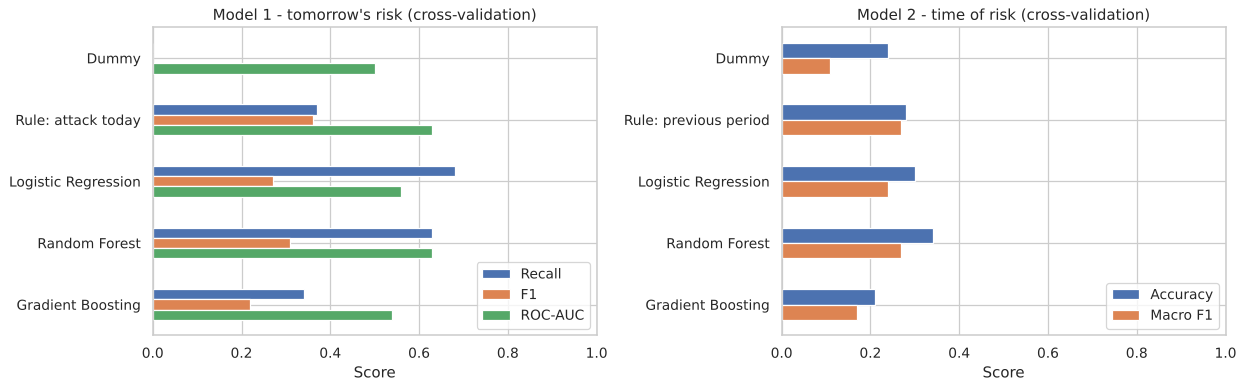

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cv1_table[["Recall", "F1", "ROC-AUC"]].plot.barh(ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Model 1 - tomorrow's risk (cross-validation)")
cv2_table[["Accuracy", "Macro F1"]].plot.barh(ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Model 2 - time of risk (cross-validation)")
for ax in axes:
    ax.set_xlim(0, 1); ax.set_xlabel("Score"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation:** 
**Model 1 (tomorrow's risk):**
- **Random Forest** is the best model: ROC-AUC **0.63** (same as the rule) and recall **0.63** instead of 0.37, so it catches many more attack days, at the cost of more false alarms (precision 0.20). F1 is still below the rule (0.31 vs 0.36) before tuning.
- **Logistic Regression** catches the most (recall 0.68) but with too many false alarms (precision 0.17).
- **Gradient Boosting** is the weakest (F1 0.22, ROC-AUC 0.54). It overfits our small data, as expected.

**Model 2 (time of risk):**
- **Random Forest** is the best: accuracy **0.34** vs 0.28 for the rule, with the same macro F1 (0.27).
- Logistic Regression is close (accuracy 0.30); Gradient Boosting is again the weakest (0.21).
- The time of an attack is harder to predict than whether one will happen, and 116 training alerts are few for 4 classes.

### 5.4 Light tuning
We tune **all three models** with a **small grid** and the same pooled time-based CV, then pick the best **tuned** model of each task. Tuning every model is fairer than tuning only the default winner: a model that looks weak with default settings may become the best once tuned. A big grid on small data would just find settings that fit the noise, so the grids stay small.

In [27]:
GRIDS = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__n_estimators": [200, 500],
                      "model__max_depth": [3, 5, None],
                      "model__min_samples_leaf": [3, 5, 10]},
    "Gradient Boosting": {"model__max_depth": [2, 3],
                          "model__learning_rate": [0.03, 0.1],
                          "model__max_iter": [100, 200]},
}

def tune(model, grid, X, y, folds, binary, metric):
    """Small grid search with the same pooled time-based CV."""
    results = []
    for params in ParameterGrid(grid):
        results.append((model_cv(clone(model).set_params(**params), X, y, folds, binary)[metric], params))
    best_score, best_params = max(results, key=lambda r: r[0])
    return clone(model).set_params(**best_params), best_params, best_score

tuned1 = {name: tune(m, GRIDS[name], X1_train, y1_train, folds1, True, "F1") for name, m in models1.items()}
tuned2 = {name: tune(m, GRIDS[name], X2_train, y2_train, folds2, False, "Macro F1") for name, m in models2.items()}

tuning_table = pd.DataFrame({
    "M1 F1 before": cv1_table.loc[list(models1), "F1"],
    "M1 F1 after": {n: t[2] for n, t in tuned1.items()},
    "M2 macro F1 before": cv2_table.loc[list(models2), "Macro F1"],
    "M2 macro F1 after": {n: t[2] for n, t in tuned2.items()},
}).round(2)
print(tuning_table.to_string())

best_name1 = max(tuned1, key=lambda n: tuned1[n][2])
best_name2 = max(tuned2, key=lambda n: tuned2[n][2])
best_m1, best_m2 = tuned1[best_name1][0], tuned2[best_name2][0]
print(f"\nModel 1 best: {best_name1} {tuned1[best_name1][1]}")
print(f"Model 2 best: {best_name2} {tuned2[best_name2][1]}")

# All metrics of the chosen tuned models, next to the baselines
print("\nModel 1 after tuning vs rule:")
print(pd.DataFrame({"Rule: attack today": cv1["Rule: attack today"],
                    f"Tuned {best_name1}": model_cv(best_m1, X1_train, y1_train, folds1, binary=True)}).T.round(2))
print("\nModel 2 after tuning vs rule:")
print(pd.DataFrame({"Rule: previous period": cv2["Rule: previous period"],
                    f"Tuned {best_name2}": model_cv(best_m2, X2_train, y2_train, folds2, binary=False)}).T.round(2))

                     M1 F1 before  M1 F1 after  M2 macro F1 before  M2 macro F1 after
Logistic Regression          0.27         0.34                0.24               0.31
Random Forest                0.31         0.36                0.27               0.27
Gradient Boosting            0.22         0.27                0.17               0.17

Model 1 best: Random Forest {'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 500}
Model 2 best: Logistic Regression {'model__C': 0.01}

Model 1 after tuning vs rule:
                     Recall  Precision    F1  ROC-AUC
Rule: attack today     0.37       0.35  0.36     0.63
Tuned Random Forest    0.73       0.24  0.36     0.65

Model 2 after tuning vs rule:
                           Accuracy  Macro F1
Rule: previous period          0.28      0.27
Tuned Logistic Regression      0.36      0.31


**Interpretation:**
- **Model 1:** tuning helps every model, and **Random Forest** stays the best (F1 **0.36**). Its best settings use **shallow trees** (`max_depth=3`) with larger leaves (`min_samples_leaf=10`). After tuning: recall **0.73** (about **twice** the rule's 0.37), F1 equal to the rule and ROC-AUC **0.65** (above the rule's 0.63).
- **Model 2:** tuning changes the winner. **Logistic Regression** rises from 0.24 to **0.31** macro F1 and overtakes Random Forest (0.27). Its best setting is `C=0.01`, which means **strong regularization** (a very simple model). It now beats the rule on both metrics: accuracy **0.36** vs 0.28, macro F1 **0.31** vs 0.27.
- In both tasks, the winning settings are the **simpler** ones. This confirms that with our data size, simpler models are more reliable.
- Tuning all three models was worth it: had we tuned only the default winner, we would have missed the better Model 2.

### 5.5 Modeling summary
| | Model 1 (tomorrow's risk) | Model 2 (time of risk) |
|---|---|---|
| Best model | **Random Forest** (`max_depth=3`, `min_samples_leaf=10`, 500 trees) | **Logistic Regression** (`C=0.01`) |
| Cross-validation score | Recall 0.73, F1 0.36, ROC-AUC 0.65 | Accuracy 0.36, macro F1 0.31 |
| Best baseline | Rule "attack today": recall 0.37, F1 0.36, ROC-AUC 0.63 | Rule "previous period": accuracy 0.28, macro F1 0.27 |
| Gradient Boosting | Weakest: overfits small data | Weakest: overfits small data |

**Honest note:** the scores are modest. Attacks are decided by the attacker, so the signal in past alerts is limited, and our data covers only 71 days. Still, Model 1 catches about **twice as many attack days** as the simple rule, and Model 2 is right more often than the rule. In section 6 we test both models **once** on the untouched test weeks (20 October – 9 November).

## 6. Evaluation on the test weeks
Now we use the **untouched test set** (20 October – 9 November) for the first and only time. Each final model is trained on the **whole training period** (1 September – 19 October) and then predicts the test weeks. The baselines are scored on the same weeks, so the comparison is fair.

### 6.1 Test scores vs baselines

In [28]:
final_m1 = clone(best_m1).fit(X1_train, y1_train)
final_m2 = clone(best_m2).fit(X2_train, y2_train)

# Model 1
p1_model = final_m1.predict(X1_test)
p1_rule = (X1_test["region_alerts_today"] > 0).astype(int)
test1 = pd.DataFrame({
    "Dummy": score(y1_test, np.zeros(len(y1_test), dtype=int), np.zeros(len(y1_test)), binary=True),
    "Rule: attack today": score(y1_test, p1_rule, p1_rule, binary=True),
    f"{best_name1} (ours)": score(y1_test, p1_model, final_m1.predict_proba(X1_test)[:, 1], binary=True),
}).T.round(2)

# Model 2
p2_model = final_m2.predict(X2_test)
p2_rule = X2_test["prev_period_region"].replace("First", y2_train.mode()[0])
p2_dummy = np.full(len(y2_test), y2_train.mode()[0])
test2 = pd.DataFrame({
    "Dummy": score(y2_test, p2_dummy, None, binary=False),
    "Rule: previous period": score(y2_test, p2_rule, None, binary=False),
    f"{best_name2} (ours)": score(y2_test, p2_model, None, binary=False),
}).T.round(2)

print("Model 1 - tomorrow's risk (test weeks):")
print(test1)
print("\nModel 2 - time of risk (test weeks):")
print(test2)

Model 1 - tomorrow's risk (test weeks):
                      Recall  Precision    F1  ROC-AUC
Dummy                   0.00       0.00  0.00     0.50
Rule: attack today      0.37       0.38  0.37     0.57
Random Forest (ours)    0.78       0.33  0.47     0.65

Model 2 - time of risk (test weeks):
                            Accuracy  Macro F1
Dummy                           0.14      0.06
Rule: previous period           0.22      0.21
Logistic Regression (ours)      0.41      0.37


**Interpretation:** 
**Model 1 (tomorrow's risk):** our Random Forest beats both baselines on **every metric**.
- It catches **78%** of attack days (36 of 46), about **twice** the rule's 37%.
- F1 rises from 0.37 to **0.47**, and ROC-AUC from 0.57 to **0.65**.
- The scores are even a bit higher than in cross-validation, because the test weeks were more active (27% attack days vs 14% in training).

**Model 2 (time of risk):** our Logistic Regression is right **41%** of the time vs 22% for the rule, and macro F1 is **0.37** vs 0.21. The test weeks had many more morning alerts than training (35% vs 15%), and the model still handles them well. Section 6.4 shows that most of this gain comes from the synthetic `school_in_person` feature.

### 6.2 Confusion matrices
A confusion matrix shows **which mistakes** each model makes, not just how many.

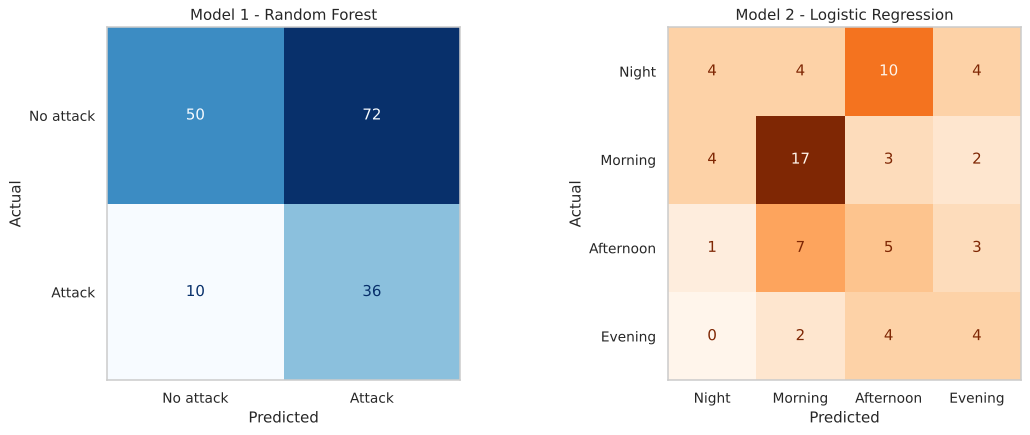

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y1_test, p1_model, display_labels=["No attack", "Attack"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Model 1 - {best_name1}")
ConfusionMatrixDisplay.from_predictions(y2_test, p2_model, labels=PERIODS,
                                        cmap="Oranges", ax=axes[1], colorbar=False)
axes[1].set_title(f"Model 2 - {best_name2}")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import classification_report
print("Model 2 - per-period results on the test weeks:")
print(classification_report(y2_test, p2_model, labels=PERIODS, zero_division=0))

Model 2 - per-period results on the test weeks:
              precision    recall  f1-score   support

       Night       0.44      0.18      0.26        22
     Morning       0.57      0.65      0.61        26
   Afternoon       0.23      0.31      0.26        16
     Evening       0.31      0.40      0.35        10

    accuracy                           0.41        74
   macro avg       0.39      0.39      0.37        74
weighted avg       0.42      0.41      0.39        74



**Interpretation:** 
**Model 1:**
- It misses only **10** attack days out of 46.
- The price is **72 false alarms** out of 122 quiet days. For an early-warning tool this is the safer mistake: an unnecessary warning costs much less than a missed attack.

**Model 2:**
- **Morning** is its strongest period: it finds **65%** of the morning alerts (17 of 26), and when it says "Morning" it is right 57% of the time.
- **Night** is the weakest: it finds only 4 of 22 night alerts, and many of them are predicted as Afternoon (10). In training, Night and Evening were the most common periods, but in the test weeks the pattern moved toward mornings.
- Afternoon and Evening are in the middle (31% and 40% found).

### 6.3 ROC curve (Model 1)
The ROC curve shows the model at **every possible alarm threshold**, not just 50%. The further the curve is above the diagonal, the better the model ranks risky days above quiet ones. The simple rule is a single point, because it can only say yes or no.

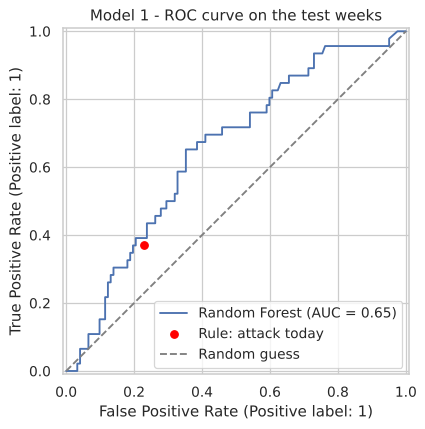

In [31]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(final_m1, X1_test, y1_test, ax=ax, name=best_name1)
fpr_rule = ((p1_rule == 1) & (y1_test == 0)).sum() / (y1_test == 0).sum()
ax.scatter(fpr_rule, recall_score(y1_test, p1_rule), color="red", zorder=3, label="Rule: attack today")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
ax.set_title("Model 1 - ROC curve on the test weeks")
ax.legend(loc="lower right")
plt.show()

**Interpretation:** the curve stays **above the diagonal** at almost every threshold, so the model ranks risky days above quiet ones better than chance (AUC **0.65**). The rule's point sits close to the curve at a low alarm rate: the model can match it there, **and** it can move up the curve to catch many more attacks when we accept more false alarms. This flexibility is what lets us show a **risk percentage** in the app.

### 6.4 Which features matter?
We use **permutation importance** on the test weeks: shuffle one feature at a time and measure how much the score drops. A big drop means the model really relies on that feature. It works the same way for both models and uses the original feature names.

Model 1: {'Region': 0.027, 'region_alerts_last_7d': 0.013, 'region_alerts_last_3d': 0.008, 'region_avg_duration_7d': 0.002, 'tomorrow_is_weekend': -0.0, 'region_alerts_today': -0.003, 'region_days_since_last': -0.004}
Model 2: {'school_in_person': 0.127, 'prev_period_region': 0.027, 'Region': 0.027, 'region_alerts_prev_7d': 0.007, 'is_weekend': -0.01, 'region_days_since_prev': -0.014}


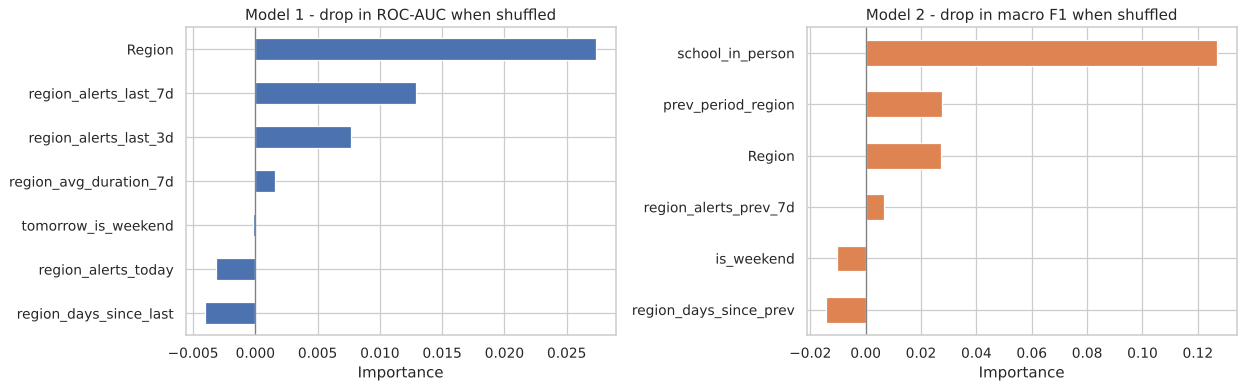

In [32]:
from sklearn.inspection import permutation_importance

imp1 = permutation_importance(final_m1, X1_test, y1_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE)
imp2 = permutation_importance(final_m2, X2_test, y2_test, scoring="f1_macro",
                              n_repeats=30, random_state=RANDOM_STATE)
imp1 = pd.Series(imp1.importances_mean, index=M1_FEATURES).sort_values()
imp2 = pd.Series(imp2.importances_mean, index=M2_FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
imp1.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Model 1 - drop in ROC-AUC when shuffled")
imp2.plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Model 2 - drop in macro F1 when shuffled")
for ax in axes:
    ax.axvline(0, color="grey", lw=1); ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()
print("Model 1:", imp1.sort_values(ascending=False).round(3).to_dict())
print("Model 2:", imp2.sort_values(ascending=False).round(3).to_dict())

**Interpretation:** 
**Model 1:**
- **`Region`** matters most: some regions (Najran, Asir, Jazan, Riyadh) are attacked far more often.
- Next come recent activity in the region: **alerts in the last 7 days** and **last 3 days**. Attacks come in waves, so a busy week means a higher risk tomorrow.
- The other features are close to zero. Small negative values mean that shuffling them changed nothing: this is noise, not harm.

**Model 2:**
- **`school_in_person`** is by far the most important feature (drop of **0.13** in macro F1). The model learned: in-person → "Morning"; otherwise → mostly "Afternoon".
- `prev_period_region` and `Region` follow far behind; the rest is close to zero.

**How much depends on the synthetic feature?** `school_in_person` was simulated **from the alerts themselves** (days with a morning alert were made in-person 90% of the time). On historical days, it therefore carries part of the answer, so the test score of Model 2 is **optimistic**. To be transparent, we score the same model **without** this feature:

In [33]:
no_school = [f for f in M2_FEATURES if f != "school_in_person"]
m2_no_school = Pipeline([("prep", make_preprocessor(no_school, ["Region", "prev_period_region"])),
                         ("model", clone(final_m2.named_steps["model"]))]).fit(X2_train[no_school], y2_train)
pd.DataFrame({
    "Rule: previous period": test2.loc["Rule: previous period"],
    f"{best_name2} with school_in_person": test2.loc[f"{best_name2} (ours)"],
    f"{best_name2} without school_in_person": score(y2_test, m2_no_school.predict(X2_test[no_school]), None, binary=False),
}).T.round(2)

,Accuracy,Macro F1
Rule: previous period,0.22,0.21
Logistic Regression with school_in_person,0.41,0.37
Logistic Regression without school_in_person,0.26,0.22


**Interpretation:** without the synthetic feature, Model 2 drops to **26%** accuracy and macro F1 **0.22**, close to the rule (22% / 0.21). So the patterns in past alerts alone predict the time only slightly better than the rule; the big gain comes from knowing whether school is in-person. In the app, the **user** gives this information for tomorrow, so the feature is legitimate there. But its real value depends on how well our simulation matches reality, which we can't fully verify.

### 6.5 Model 1 by region

In [34]:
by_region = X1_test.assign(actual=y1_test.values, predicted=p1_model).groupby("Region").apply(
    lambda g: pd.Series({"Attack days": int(g["actual"].sum()),
                         "Caught": int(((g["actual"] == 1) & (g["predicted"] == 1)).sum()),
                         "False alarms": int(((g["actual"] == 0) & (g["predicted"] == 1)).sum())}),
    include_groups=False)
by_region["Recall"] = (by_region["Caught"] / by_region["Attack days"].replace(0, np.nan)).round(2)
by_region.sort_values("Attack days", ascending=False)

,Attack days,Caught,False alarms,Recall
Region,,,,
Najran,12,12,9,1.00
Riyadh,10,9,11,0.90
Asir,7,6,14,0.86
Jazan,7,7,13,1.00
Makkah,4,2,9,0.50
Eastern Province,3,0,7,0.00
Madinah,3,0,9,0.00
Tabuk,0,0,0,NaN


**Interpretation:** 
- In the **high-risk regions** the model catches almost every attack day: Najran 12 of 12, Jazan 7 of 7, Riyadh 9 of 10, Asir 6 of 7.
- In regions with **few alerts** (Makkah, Eastern Province, Madinah) it catches only 2 of 10. There are too few examples in training for the model to learn when these regions get attacked.
- False alarms are spread over all regions. They are highest in Asir (14) and Jazan (13), which the model sees as constantly at risk.

### 6.6 Evaluation summary
| | Model 1 (tomorrow's risk) | Model 2 (time of risk) |
|---|---|---|
| Final model | Random Forest | Logistic Regression |
| Test score | Recall **0.78**, F1 **0.47**, ROC-AUC **0.65** | Accuracy **0.41**, macro F1 **0.37** (0.26 / 0.22 without `school_in_person`) |
| Best baseline on test | Rule "attack today": recall 0.37, F1 0.37, ROC-AUC 0.57 | Rule "previous period": accuracy 0.22, macro F1 0.21 |
| Strength | Catches most attack days, especially in high-risk regions | Finds most morning alerts |
| Weakness | Many false alarms; weak in low-activity regions | Misses most night alerts; relies heavily on the synthetic school feature |
| Most useful features | `Region`, alerts in the last 7 and 3 days | `school_in_person`, far ahead of the rest |

**Conclusion:** both models beat the simple rules on unseen weeks. **Model 1 is clearly useful** as an early-warning signal. **Model 2's gain comes mainly from the school information**, so it should be shown in the app as a hint, not a certainty. The main limit is the data: 71 days and a pattern that shifts over time.

## 7. Model Selection
### 7.1 Comparing all candidates
To justify our choice, we put the three models side by side: their **cross-validation** score (used to choose) and their **test** score (used only to confirm). Every model gets the same tuning grid and the same time-based folds.

In [35]:
rows1, rows2 = {}, {}
for name, (m, _, _) in tuned1.items():
    cv = model_cv(m, X1_train, y1_train, folds1, binary=True)
    fit = clone(m).fit(X1_train, y1_train)
    te = score(y1_test, fit.predict(X1_test), fit.predict_proba(X1_test)[:, 1], binary=True)
    rows1[name] = {"CV F1": cv["F1"], "CV ROC-AUC": cv["ROC-AUC"],
                   "Test Recall": te["Recall"], "Test F1": te["F1"], "Test ROC-AUC": te["ROC-AUC"]}
for name, (m, _, _) in tuned2.items():
    cv = model_cv(m, X2_train, y2_train, folds2, binary=False)
    fit = clone(m).fit(X2_train, y2_train)
    te = score(y2_test, fit.predict(X2_test), None, binary=False)
    rows2[name] = {"CV Macro F1": cv["Macro F1"], "CV Accuracy": cv["Accuracy"],
                   "Test Macro F1": te["Macro F1"], "Test Accuracy": te["Accuracy"]}

print("Model 1 - tomorrow's risk (all models tuned):")
print(pd.DataFrame(rows1).T.round(2))
print("\nModel 2 - time of risk (all models tuned):")
print(pd.DataFrame(rows2).T.round(2))

Model 1 - tomorrow's risk (all models tuned):
                     CV F1  CV ROC-AUC  Test Recall  Test F1  Test ROC-AUC
Logistic Regression   0.34        0.64         0.72     0.46          0.66
Random Forest         0.36        0.65         0.78     0.47          0.65
Gradient Boosting     0.27        0.61         0.78     0.51          0.66

Model 2 - time of risk (all models tuned):
                     CV Macro F1  CV Accuracy  Test Macro F1  Test Accuracy
Logistic Regression         0.31         0.36           0.37           0.41
Random Forest               0.27         0.34           0.25           0.28
Gradient Boosting           0.17         0.22           0.21           0.22


**Interpretation:**
- **Model 1:** Random Forest has the best cross-validation F1 (**0.36**) and ROC-AUC (**0.65**). On the test, Gradient Boosting has a slightly higher F1 (0.51 vs 0.47), but its cross-validation is the weakest (0.27). Choosing it because of the test would be **choosing by luck on 3 weeks of data**, so we stay with the model that was best when we chose.
- **Model 2:** Logistic Regression is best in cross-validation (**0.31**) **and** on the test (**0.37**), so the choice is confirmed.

### 7.2 Final choice
| Task | Chosen model | Why |
|---|---|---|
| **Tomorrow's risk** | **Random Forest** (`max_depth=3`, `min_samples_leaf=10`, 500 trees) | Best cross-validation F1 and ROC-AUC; on the test it catches 78% of attack days, twice the rule; shallow trees resist overfitting; gives a probability we can show as a risk % |
| **Time of risk** | **Logistic Regression** (`C=0.01`) | Best in cross-validation and on the test; the simplest model, which suits 190 alerts; gives a probability for each period |
| Time until danger clears | No model: median per region | Durations are short and stable (median 7 min), so a statistic is clearer and more honest than a model |

**Why not Gradient Boosting (the XGBoost family)?** It was the weakest in cross-validation for both tasks. Boosting shines on large datasets; on ours, it fits the noise.

### 7.3 Retraining on all the data
The test weeks are the **most recent** and the most useful for predicting what comes next, so the app shouldn't ignore them. Now that the evaluation is done, we retrain both chosen models, **with the same settings**, on **all** the data (1 September – 9 November). The scores in section 6 remain our honest estimate of performance.

We also save:
- the **median time until danger clears** per region (output 3: statistics, no model);
- the feature lists and periods, so the app uses exactly the same inputs.

In [36]:
import joblib, json
from pathlib import Path

X1_all, y1_all = d[M1_FEATURES], d["attack_tomorrow"].astype(int)
X2_all, y2_all = timing[M2_FEATURES], timing["period"]
model1 = clone(best_m1).fit(X1_all, y1_all)
model2 = clone(best_m2).fit(X2_all, y2_all)

clear_minutes = alerts.groupby("Region")["duration_min"].median().round(1)

out = Path("models"); out.mkdir(exist_ok=True)
joblib.dump(model1, out / "model1_attack_tomorrow.joblib")
joblib.dump(model2, out / "model2_period.joblib")
json.dump({"m1_features": M1_FEATURES, "m2_features": M2_FEATURES, "periods": PERIODS,
           "regions": regions, "weekend": WEEKEND, "start_date": START_DATE,
           "median_clear_minutes": clear_minutes.to_dict(),
           "trained_until": str(days.max().date())},
          open(out / "model_info.json", "w"), indent=2)

print(f"Model 1 trained on {len(X1_all)} rows ({y1_all.sum()} attacks)")
print(f"Model 2 trained on {len(X2_all)} alerts")
print("Saved:", sorted(p.name for p in out.iterdir()))

Model 1 trained on 560 rows (99 attacks)
Model 2 trained on 190 alerts
Saved: ['model1_attack_tomorrow.joblib', 'model2_period.joblib', 'model_info.json']


### 7.4 Example: the predictions for 11 November
This is exactly what the app will compute. The features for "tomorrow" come only from alerts **up to 10 November**. For Model 2, the user chooses whether school is in-person tomorrow, so we show both answers.

In [37]:
def tomorrow_inputs(alerts, today):
    """Build Model 1 and Model 2 inputs for the day after `today`, for every region."""
    tomorrow = today + pd.Timedelta(days=1)
    x1 = daily[daily["date"] == today].set_index("Region", drop=False)[M1_FEATURES]
    rows = []
    for region in regions:
        earlier = alerts[(alerts["Region"] == region) & (alerts["date"] <= today)]
        last = earlier.iloc[-1] if len(earlier) else None
        rows.append({
            "Region": region,
            "is_weekend": int(tomorrow.day_name() in WEEKEND),
            "prev_period_region": last["period"] if last is not None else "First",
            "region_days_since_prev": (tomorrow - last["date"]).days if last is not None
                                      else (tomorrow - pd.Timestamp(START_DATE)).days,
            "region_alerts_prev_7d": int((earlier["date"] >= tomorrow - pd.Timedelta(days=7)).sum()),
        })
    return x1, pd.DataFrame(rows).set_index("Region"), tomorrow

today = days.max()
x1, x2, tomorrow = tomorrow_inputs(alerts, today)
pred = pd.DataFrame(index=regions)
pred["Attack risk (%)"] = (model1.predict_proba(x1.loc[regions])[:, 1] * 100).round(0).astype(int)
pred["Attack expected"] = model1.predict(x1.loc[regions])
for school_value, label in [(1, "in-person"), (0, "remote")]:
    x2s = x2.assign(school_in_person=school_value).reset_index()[M2_FEATURES]
    pred[f"Likely time (school {label})"] = model2.predict(x2s)
pred["Median clear time (min)"] = clear_minutes.reindex(regions).values
print("Predictions for", tomorrow.date(), f"({tomorrow.day_name()})")
pred.sort_values("Attack risk (%)", ascending=False)

Predictions for 2026-11-11 (Wednesday)


,Attack risk (%),Attack expected,Likely time (school in-person),Likely time (school remote),Median clear time (min)
Asir,70,1,Morning,Afternoon,6.0
Riyadh,70,1,Morning,Afternoon,9.5
Najran,68,1,Morning,Afternoon,5.0
Eastern Province,57,1,Morning,Afternoon,10.5
Jazan,55,1,Morning,Afternoon,6.0
Madinah,42,0,Morning,Afternoon,9.5
Makkah,30,0,Morning,Afternoon,10.0
Tabuk,20,0,Morning,Night,9.0


**Interpretation:**
- **Tomorrow's risk:** Asir, Riyadh and Najran get about **70%**, followed by Eastern Province (57%) and Jazan (55%); Tabuk is lowest (20%). This follows the recent activity in each region.
- **Time of risk:** the answer depends almost only on the school input: **Morning** if school is in-person, **Afternoon** if it's remote (Night for Tabuk). This matches what we found in 6.4.
- **Time until danger clears:** from 5 minutes (Najran) to 10.5 minutes (Eastern Province).

### 7.5 Model selection summary
- **Final models:** Random Forest for tomorrow's risk and Logistic Regression for the time of risk, both chosen by cross-validation and confirmed on the test weeks.
- **Retrained on all data** (560 day-region rows and 190 alerts) and saved in `models/` with the feature lists and median clear times.
- **What the app shows per region:** the risk % for tomorrow, the likely time (the user tells us whether school is in-person), and the usual time until danger clears.
- **Limits to state clearly:** many false alarms in Model 1, and Model 2 relies on the synthetic school feature. More data is the main way to improve both.

## 8. Deployment (Streamlit)
We deploy the models as a **Streamlit** web app. Streamlit turns a Python script into an interactive page, so the same code style as this notebook runs the app, and it can be hosted for free on Streamlit Community Cloud straight from our GitHub repo.

**Project files:**

| File | Role |
|---|---|
| `app.py` | The Streamlit page |
| `features.py` | Cleans the tweets and builds the model inputs, with the **same logic as this notebook** |
| `models/` | The two trained models and `model_info.json` (features, regions, median clear times) saved in section 7.3 |
| `SaudiDCD_alerts.csv` | Our collected tweets |
| `requirements.txt` | Libraries for the hosting server |

**What the user does:**
1. Chooses a **region**.
2. Says whether **school is in-person tomorrow** in that region (needed by Model 2).
3. Optionally uploads a **newer tweets file**, so the predictions use the latest activity.

**What the app shows:**
1. **Tomorrow's risk** as a percentage and a level: High ≥ 50% (the model's own alarm), Medium 35–49%, Low below 35%.
2. The **most likely time of day**, with the chance of each period.
3. The **usual time until danger clears** (median for the region).
4. An overview chart of tomorrow's risk in **all regions**.

A clear note says the tool **does not replace official warnings**.

### 8.1 Checking that the app predicts exactly like the notebook
The app builds its inputs with `features.py`, not with the notebook code. To be sure both give the same answers, we rebuild the 11 November inputs with `features.py` and compare them with section 7.4.

In [38]:
from features import clean_alerts, model1_inputs, model2_inputs

app_alerts = clean_alerts(pd.read_csv("SaudiDCD_alerts.csv"))
app_x1 = model1_inputs(app_alerts, regions, today)[M1_FEATURES]
app_risk = (model1.predict_proba(app_x1)[:, 1] * 100).round(0).astype(int)

# compare values (counts are whole numbers in the app and floats from rolling sums in the notebook)
same_m1 = (app_x1.reset_index(drop=True).astype(str).replace(r"\.0$", "", regex=True)
           .equals(x1.loc[regions, M1_FEATURES].reset_index(drop=True).astype(str).replace(r"\.0$", "", regex=True)))
same_m2 = all(
    (model2_inputs(app_alerts, regions, today, {r: s for r in regions})[M2_FEATURES].reset_index(drop=True)
     .equals(x2.assign(school_in_person=s).reset_index()[M2_FEATURES]))
    for s in (0, 1))
print("Model 1 inputs identical:", same_m1)
print("Model 2 inputs identical:", same_m2)
print("Risk % from the app:", dict(zip(regions, app_risk.tolist())))

Model 1 inputs identical: True
Model 2 inputs identical: True
Risk % from the app: {'Asir': 70, 'Eastern Province': 57, 'Jazan': 55, 'Madinah': 42, 'Makkah': 30, 'Najran': 68, 'Riyadh': 70, 'Tabuk': 20}


**Interpretation:** the inputs built by `features.py` are **identical** to the notebook's, and the risk percentages match section 7.4 exactly (Asir and Riyadh 70%, Najran 68%, … Tabuk 20%). The app therefore shows exactly what we evaluated.

### 8.2 Running and publishing the app
**Locally:**
```
pip install -r requirements.txt
streamlit run app.py
```

**Online (Streamlit Community Cloud):**
1. Push the project files to GitHub.
2. On share.streamlit.io, choose **New app**, select the repo and `app.py`, then **Deploy**.
3. Share the link in the presentation.

`scikit-learn` is pinned to the same version used for training, because saved models must be loaded with the version that created them.

### 8.3 Final summary
| Step | What we did |
|---|---|
| Problem | Early warning per Saudi region: risk tomorrow, likely time, time until danger clears |
| Data | 190 alerts and 192 clear tweets collected from @SaudiDCD, 1 Sep – 10 Nov 2026 |
| Preprocessing | Two tables (day × region and per alert), past-only features, synthetic `school_in_person` (Model 2 only), time-based split |
| Modeling | Logistic Regression, Random Forest and Gradient Boosting, compared with time-based cross-validation and light tuning |
| Evaluation | Model 1 (Random Forest): recall 0.78, F1 0.47, twice the simple rule. Model 2 (Logistic Regression): accuracy 0.41 vs 0.22 for the rule, mostly thanks to the school feature |
| Deployment | Streamlit app with the three outputs for every region |

**Main lesson:** with 71 days of data, simple models and honest baselines matter more than complex algorithms. **Collecting more data** is the most effective next step.